In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values
from matplotlib import pyplot as plt

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Fig_04'

### Identify candidate kisspeptin populations

In [4]:
# Load marker gene table
fp_markers = DATADIR / '9_objects' / 'markers' / 'hypomap3d_cell_type_marker_genes_L4.csv'
df_markers = pd.read_csv(fp_markers)
df_markers_vs_all = df_markers[df_markers['comparison'] == 'OneVsAll']

In [5]:
df_kiss1_markers = df_markers_vs_all[df_markers_vs_all['gene_name'] == 'Kiss1']
df_kiss1_markers = df_kiss1_markers.sort_values('specificity', ascending=False)
(
    df_kiss1_markers.set_index('celltype_descr')['log2FC'] 
    * df_kiss1_markers.set_index('celltype_descr')['pctA']
).sort_values(ascending=False)

celltype_descr
Gl4-213 ARH Kiss1.Slc38a3    5.590406
Gb4-444 PVpo Il1rap.Kiss1    4.723129
Gl4-212 ARH Kiss1.Nxf3       4.553513
Gb4-441 PVpo Il1rap.Mafa     0.642128
Gb4-336 MPO Penk.Postn       0.544742
Gb4-337 MPO Penk.Arap2       0.507714
Gb4-420 MPO Cdh23.Th         0.375615
Gb4-438 MPN Nts.Kiss1        0.347502
Gl4-134 MPN Sox14.Tac2       0.335588
Gb4-422 MPO Cdh23.Meis2      0.283082
Gl4-57 LHA Igf1              0.248865
Gl4-103 LHA Ctxn3.Cpa6       0.091098
dtype: float64

In [6]:
# bonus: find GnRH ID
[x for x in df_markers_vs_all['celltype_descr'].unique() if 'Gnrh' in x]

['Gl4-1 HY Gnrh1']

### Manually define candidates

In [7]:
# Load control anndata
fp_anndata = DATADIR / '9_objects' / 'singlecell' / 'hypomap3d_singlecell_control.h5ad'
scdata = sc.read_h5ad(fp_anndata)

In [8]:
CANDIDATES = {
    'AVPV':{
        'Gb4-438': "#9467bd", # sexually dimorphic with low kiss1 expression and slight male dominance
        'Gb4-441': "#8c564b", # likely AVPV(Kiss1) but maybe 'off'
        'Gb4-444': "#17becf", # likely AVPV(Kiss1)
    },
    'GnRH':{
        'Gl4-1': "#2ca02c", # GnRH
    },
    'KNDy':{ 
        'Gl4-212': "#1f77b4", # KNDy
        'Gl4-213': "#ff7f0e", # KNDy
    }
}

In [9]:
# All celltypes start as grey
BASE_PALETTE = {
    x: "#D0D0D0"
    for x in scdata.obs['L4_ID'].cat.categories
}

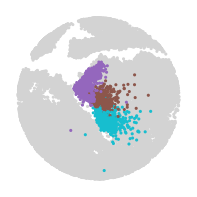

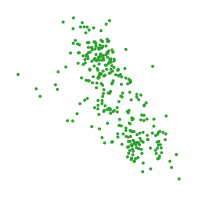

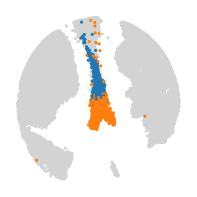

In [10]:
from hm3d_utils.plotting import zoom_embedding_circular

for name, celltype_color_map in CANDIDATES.items():
    
    # Create interest mask
    mask = scdata.obs['L4_ID'].isin(celltype_color_map)
    
    # Update palettes
    palette = BASE_PALETTE.copy()
    palette.update(celltype_color_map)
    
    # Initialise figure
    fig, ax = plt.subplots(1,1, figsize=(45*MM, 45*MM))
    
    zoom_embedding_circular(
        scdata,
        basis='X_umap',
        color='L4_ID',
        interest_mask=mask,
        palette=palette, 
        title='', 
        size=20,
        legend_loc=None, 
        margin=0.5, 
        frameon=False, 
        add_outline=False,
        show=False,
        include_background=True,
        ax=ax
    )
    
    fig.subplots_adjust(bottom=0, top=1, left=0, right=1)

    fig.savefig(FIGUREDIR / f'subplot_e_{name}.png', dpi=600, transparent=True)
    
    plt.show()

### Subplot F: DotPlot

In [11]:
# normalize single cell anndata
sc.pp.normalize_total(scdata, target_sum=10_000)
sc.pp.log1p(scdata)

In [12]:
# Manually define markers of interest
MARKERS = {
    'Gl/Gb': ['Slc17a6', 'Slc32a1'],
    'KNDy': ['Kiss1', 'Tac2', 'Pdyn', ],
    'Gonad': ['Esr1', 'Esr2', 'Pgr'],
    'GnRH': ['Gnrh1', 'Kiss1r', 'Npffr1'],
    'Receptors': ['Tacr1', 'Tacr3', 'Oprk1', 'Oxtr', 'Vipr2', 'Avpr1a', 'Crhr1', 'Mc3r', 'Mc4r', 'Lepr', 'Npy1r', 'Npy2r', 'Npy5r'],
}

In [15]:
[x.keys() for x in CANDIDATES.values()]

[dict_keys(['Gb4-438', 'Gb4-441', 'Gb4-444']),
 dict_keys(['Gl4-1']),
 dict_keys(['Gl4-212', 'Gl4-213'])]

In [18]:
[y.keys() for y in CANDIDATES.values()]

[dict_keys(['Gb4-438', 'Gb4-441', 'Gb4-444']),
 dict_keys(['Gl4-1']),
 dict_keys(['Gl4-212', 'Gl4-213'])]

In [33]:
# Subset to only candidates
SELECTION = [id_ for group in CANDIDATES.values() for id_ in group]

SELECTION = sorted(SELECTION, key = lambda x: int(x.split('-')[1]))

subset = scdata[scdata.obs['L4_ID'].isin(SELECTION)].copy()
subset

AnnData object with n_obs × n_vars = 6607 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'log1p'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

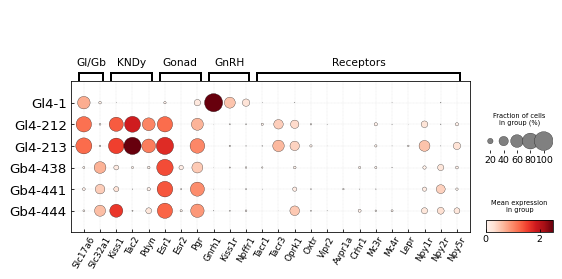

In [34]:
with plt.style.context('../../../resources/figures.mplstyle') as rc:

    plt.close('all') # a development trick
    fig, ax = plt.subplots(1, 1, figsize=(150*MM, 75*MM))
    dp = sc.pl.dotplot(
        subset, 
        MARKERS, 
        groupby='L4_ID', 
        categories_order=SELECTION,
        cmap='Reds',
        dot_min=0.01,
        swap_axes=False,
        var_group_rotation=0,
        ax=ax,
        show=False,
        vmax=2.5,
    )

    main_ax = dp['mainplot_ax']


    main_ax.spines['top'].set_visible(True)
    main_ax.spines['right'].set_visible(True)

    main_ax.set_axisbelow(True)
    main_ax.grid(which='major', color='lightgrey', linestyle='--', linewidth=0.2)

    main_ax.set_xticklabels(main_ax.get_xticklabels(), rotation=60, ha='center', va='top')
    main_ax.tick_params(axis='y', pad=3, labelsize=10)

    if 'gene_group_ax' in dp:
        for text in dp['gene_group_ax'].texts:
            text.set_fontsize(8)
            text.set_rotation(0)
            text.set_ha('center')
            text.set_va('bottom')

    dp['size_legend_ax'].title.set_size(5)
    dp['size_legend_ax'].tick_params('x', labelsize=7)

    dp['color_legend_ax'].title.set_size(5)
    dp['color_legend_ax'].tick_params('x', labelsize=7)


    fig.tight_layout()
    # fig.subplots_adjust(top=1)
    fig.savefig(FIGUREDIR / 'subplot_f_dotplot.pdf', transparent=True)

    plt.show()
    plt.close(fig)
